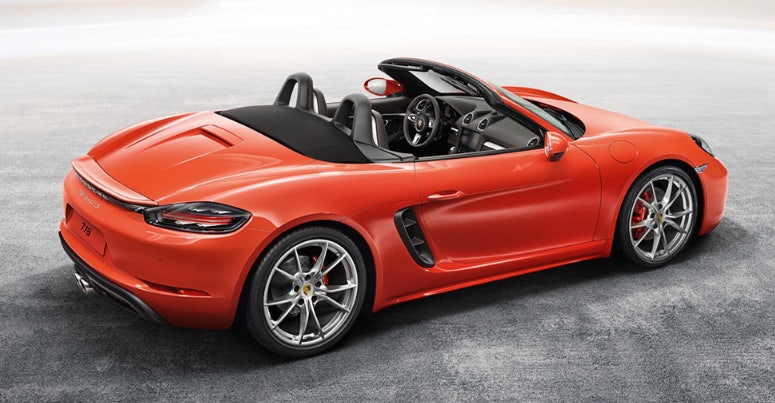

Distance: 0.0000 | path: /content/718 포르쉐.jpeg


In [ ]:
import os
import cv2
from google.colab import files
from google.colab.patches import cv2_imshow
import numpy as np

target = [
    os.path.join('/content', f)
    for f in os.listdir('/content')
    if '포르쉐' in f or f.lower().endswith(('.jpg', 'jpeg', '.png'))
][0]

def img2hash(im):
  g = cv2.resize(cv2.cvtColor(im, cv2.COLOR_BGR2GRAY), (16, 16))
  return 1 * (g > g.mean())

def haming_distance(a, b):
  return (a.reshape(1, -1) != b.reshape(1, -1)).sum()

img = cv2.imdecode(np.fromfile(target, np.uint8), cv2.IMREAD_COLOR)
cv2_imshow(img)

dst = haming_distance(img2hash(img), img2hash(img))
print(f'Distance: {dst/256:.4f} | path: {target}')

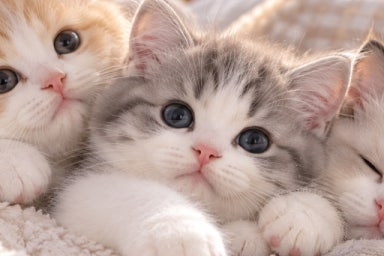

TM_CCOEFF_NORMED 1.0 (192, 128)


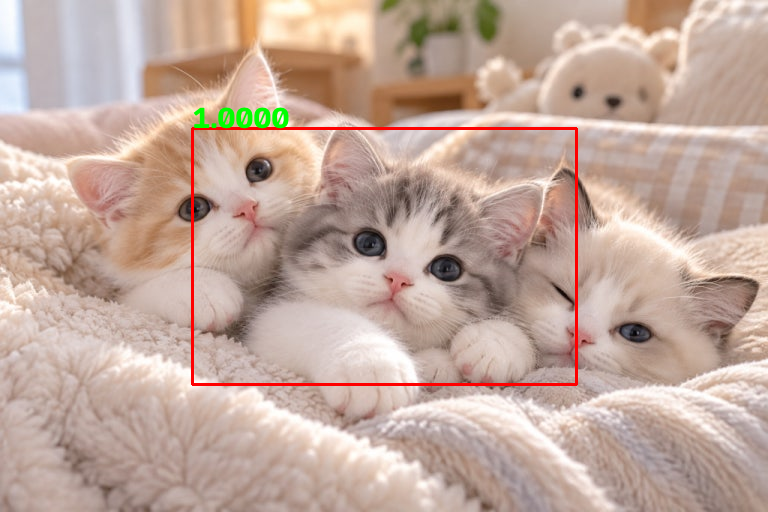

TM_CCORR_NORMED 1.0 (192, 128)


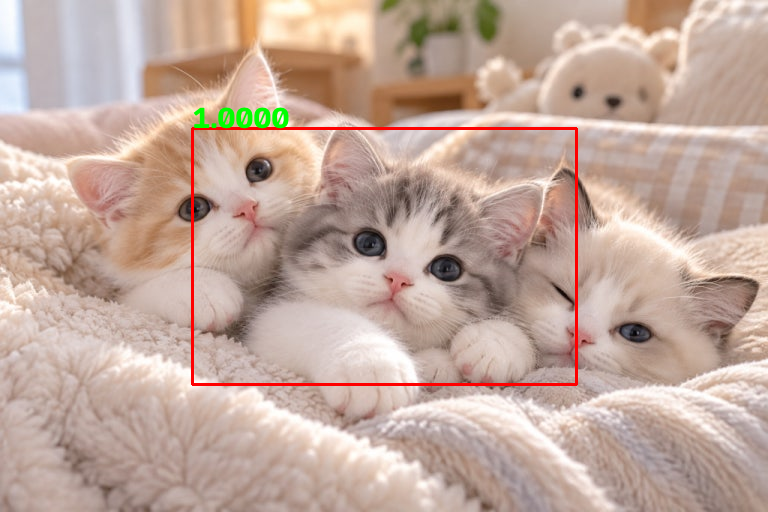

TM_SQDIFF_NORMED 0.0 (192, 128)


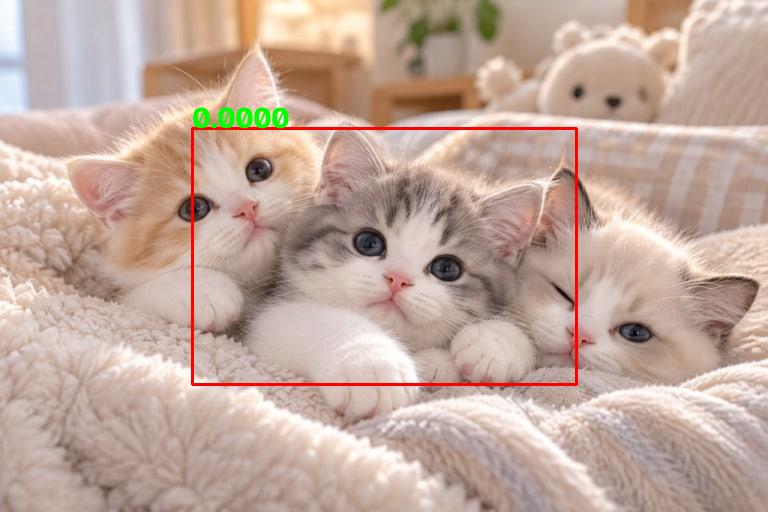

In [ ]:
import cv2,  numpy as np
from google.colab.patches import cv2_imshow
import numpy as np

def load_img(path):
  data = np.fromfile(path, np.uint8)
  return cv2.imdecode(data, cv2.IMREAD_COLOR)

img = load_img('/content/고양이.jpeg')
ih, iw = img.shape[:2]

tpl = img[ih // 4 : ih * 3 // 4, iw // 4 : iw * 3 // 4]
th, tw = tpl.shape[:2]
cv2_imshow(tpl)

methods = [
    ('TM_CCOEFF_NORMED', cv2.TM_CCOEFF_NORMED),
    ('TM_CCORR_NORMED', cv2.TM_CCORR_NORMED),
    ('TM_SQDIFF_NORMED', cv2.TM_SQDIFF_NORMED),
]

for name, method in methods:
  res = cv2.matchTemplate(img, tpl, method)
  mn, mx, mn_loc, mx_loc = cv2.minMaxLoc(res)
  pt, val = (mn_loc, mn) if method == cv2.TM_SQDIFF_NORMED else (mx_loc, mx)

  draw = img.copy()
  cv2.rectangle(draw, pt, (pt[0] + tw, pt[1] + th), (0, 0, 255), 2)
  cv2.putText(draw, f'{val:.4f}', pt, 0, 1, (0, 255, 0), 2)
  print(name, val, pt)
  cv2_imshow(draw)

파일: /content/이모티콘 모음.jpeg | 탬플릿: 80x80 | 매칭 수: 6


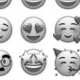

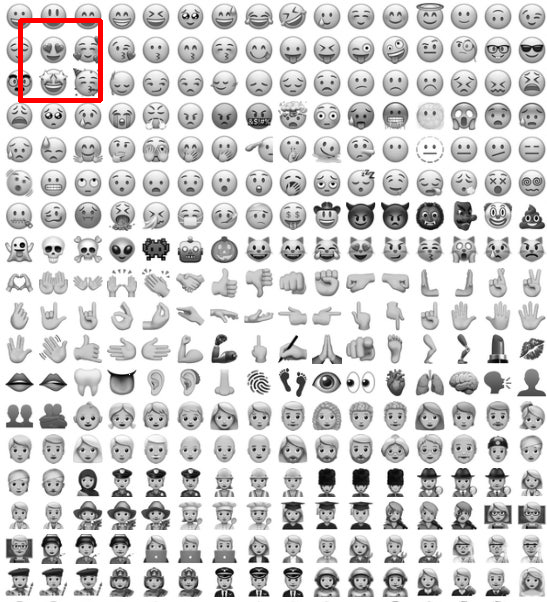

In [ ]:
import cv2
from google.colab.patches import cv2_imshow
import numpy as np

def read_gray(path):
  buf = np.fromfile(path, dtype=np.uint8)
  img = cv2.imdecode(buf, cv2.IMREAD_GRAYSCALE)
  if img is None:
    raise FileNotFoundError
  return img

target = '/content/이모티콘 모음.jpeg'
if not os.path.exists(target):
  jpegs = [
      f
      for f in os.listdir('/content')
      if f.lower().endswith(('.jpeg', '.jpg'))
  ]
  if jpegs:
    target = os.path.join('/content', jpegs[0])

src = read_gray(target)
h, w = src.shape

y1, y2, x1, x2 = 20, min(100, h), 20, min(100, w)
tpl = src[y1:y2, x1:x2]
th, tw = tpl.shape

score_map = cv2.matchTemplate(src, tpl, cv2.TM_CCOEFF_NORMED)
threshold = 0.8
ys, xs = np.where(score_map >= threshold)

out = cv2.cvtColor(src, cv2.COLOR_GRAY2BGR)
for x, y in zip(xs, ys):
  cv2.rectangle(out, (x, y), (x + tw, y + th), (0, 0, 255), 2)

print(f'파일: {target} | 탬플릿: {tw}x{th} | 매칭 수: {len(xs)}')
cv2_imshow(tpl)
cv2_imshow(out)

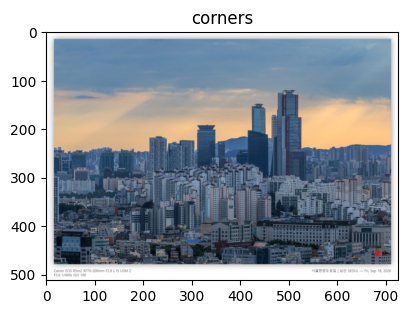

<Figure size 640x480 with 0 Axes>

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

img = cv2.imread("/content/서울.jpeg")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

resp = cv2.dilate(cv2.cornerHarris(np.float32(gray), 3, 3, 0.04), None)

out = img.copy()
out[resp > 0.08 * resp.max()] = [255, 255, 0]

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("corners")
plt.show("off")

plt.tight_layout()
plt.show()

검출된  영역 수: 0개


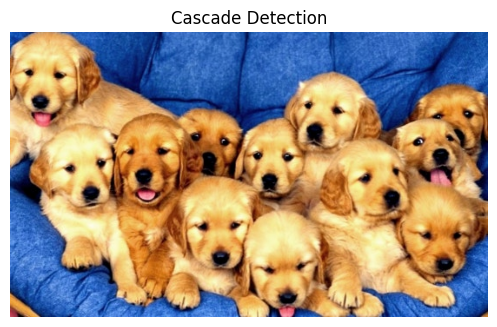

In [ ]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread("/content/강아지.jpeg")

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
result = img.copy()

import numpy as np

edges = cv2.Canny(gray, 80, 180)
contours, _ = cv2.findContours(
    edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)
boxes =[
    cv2.boundingRect(c) for c in contours if cv2.contourArea(c) > 800
]

for idx, (x, y, w, h) in enumerate(boxes, start=1):
    cv2.rectangle(result, (x, y), (x + w, y + h), (0, 255, 0), 3)
    cv2.putText(
        result, f"#{idx}", (x, max(y - 10, 20)),
        cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2
    )

print(f"검출된  영역 수: {len(boxes)}개")

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Cascade Detection")
plt.axis("off")

plt.tight_layout()
plt.show()

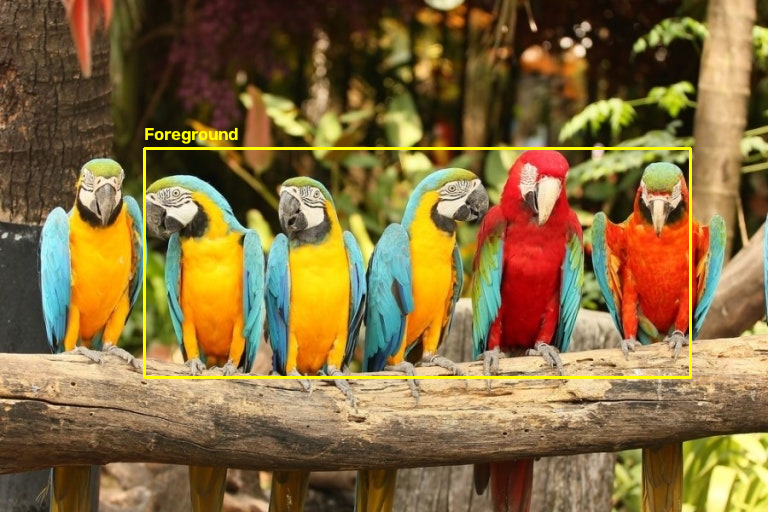

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img = cv2.imread('/content/앵무새.jpeg')
h, w, _= img.shape

mask = np.zeros((h, w), np.uint8)
bgd_model = np.zeros((1, 65), np.float64)
fgd_model = np.zeros((1, 65), np.float64)

rect = (int(w * 0.1), int(h * 0.1), int(w * 0.8), int(h * 0.8))
cv2.grabCut(img, mask, rect, bgd_model, fgd_model, 5, cv2.GC_INIT_WITH_RECT)

fg_mask = np.where((mask == 1) | (mask == 3), 255, 0).astype('uint8')

contours, _ = cv2.findContours(
    fg_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)
result = img.copy()

for cnt in contours:
  if cv2.contourArea(cnt) > (h * w) * 0.02:
    x, y, bw, bh = cv2.boundingRect(cnt)
    cv2.rectangle(result, (x, y), (x + bw, y + bh), (0, 255, 255), 2)
    cv2.putText(
    result,
    'Foreground',
    (x, max(y - 8, 15)),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.6,
    (0, 255, 255),
    2,)

cv2_imshow(result)

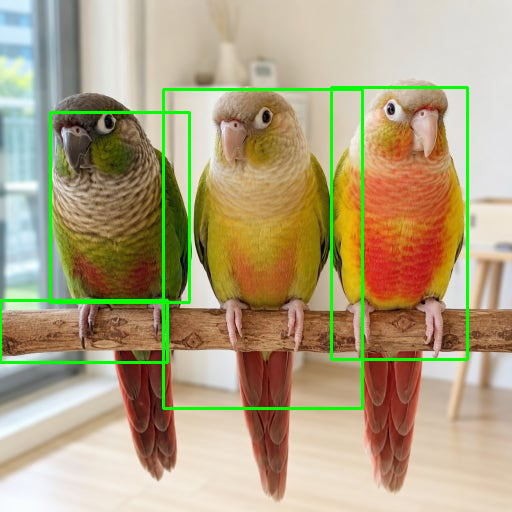

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

frame = cv2.imread('/content/코뉴어.jpeg')
hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)

lower = np.array([10, 80, 80])
upper = np.array([45, 255, 255])
mask = cv2.inRange(hsv, lower, upper)

kernel = np.ones((5, 5), np.uint8)
mask = cv2.inRange(hsv, lower, upper)

min_area = frame.shape[0] * frame.shape[1] * 0.02
contours, _=cv2.findContours(
    mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)

for c in contours:
  if cv2.contourArea(c) > min_area:
    x, y, w, h = cv2.boundingRect(c)
    cv2.rectangle(frame, (x, y), (x + w, y + h), (0, 255, 0), 2)

cv2_imshow(frame)


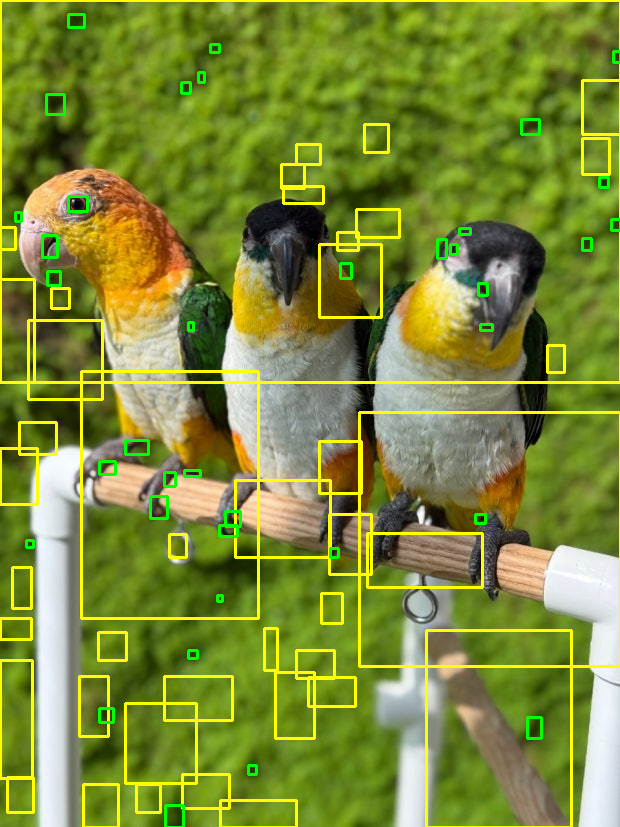

In [ ]:
import cv2
from google.colab.patches import cv2_imshow

raw = cv2.imread("카이큐.jpeg")
hsv = cv2.cvtColor(raw, cv2.COLOR_BGR2HSV)
gray = cv2.cvtColor(raw, cv2.COLOR_BGR2GRAY)

for c in cv2.findContours(
    cv2.inRange(hsv, (12, 70, 90), (38, 255, 255)),
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE,
)[0]:
  if cv2.contourArea(c) > 180:
    x, y, w, h = cv2.boundingRect(c)
    cv2.rectangle(raw, (x, y), (x + w, y + h), (0, 255, 255), 2)

for c in cv2.findContours(
    cv2.threshold(gray, 55, 255, cv2.THRESH_BINARY_INV)[1],
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE,
)[0]:
  x, y, w, h = cv2.boundingRect(c)
  if 15 < cv2.contourArea(c) < 250 and 4 < w < 25 and 4 < h < 25:
    cv2.rectangle(raw, (x, y), (x + w, y + h), (0, 255, 0), 2)

cv2_imshow(raw)

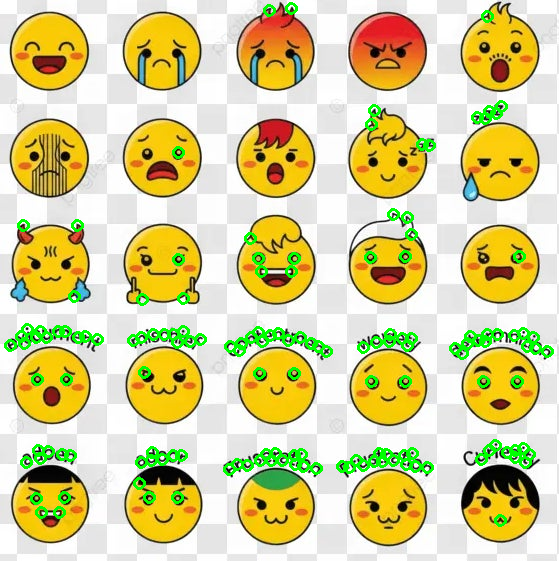

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

img = cv2.imread('이모티콘.jpeg')
output = img.copy()
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 코너 검출 (기존 100, 0.01, 5, blockSize=3, k=0.03 에서 약간 변형)
corners = cv2.goodFeaturesToTrack(
    gray,
    maxCorners=150,
    qualityLevel=0.015,
    minDistance=7,
    blockSize=5,
    useHarrisDetector=False,
    k=0.04,
)

#검출된 코너 표시 (반지름 5, 초록색, 테두리 두께 2)
if corners is not None:
  for pt in corners:
    x, y = np.int32(pt.ravel())
    cv2.circle(output, (x, y), 5, (0, 255, 0), 2)

cv2_imshow(output)

=== FAST 설정 및 검출 요약 ===
Threshold: 25
neighborhood Type: 2
keypoints (NMS=True): 2800
keypoints (NMS=False): 7353


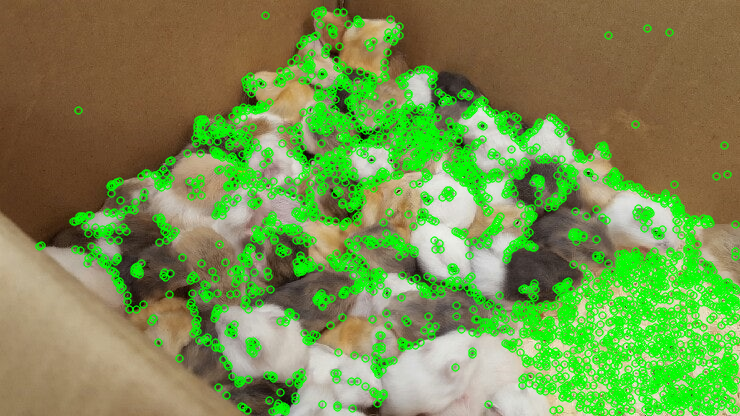

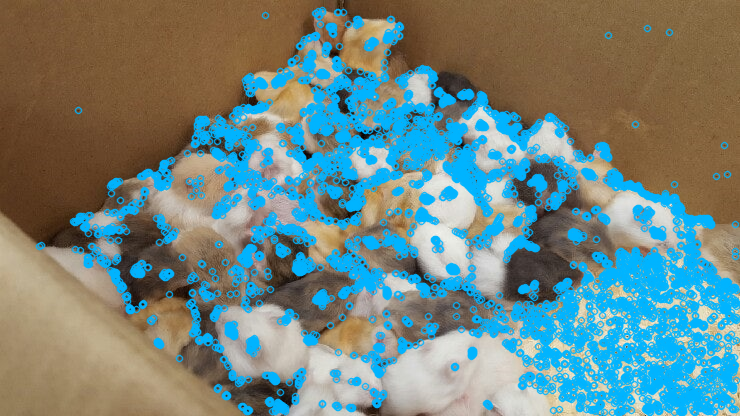

In [ ]:
import cv2
from google.colab.patches import cv2_imshow
import numpy as np

# 1. 이미지 로드 및 유효성 확인
img = cv2.imread('햄스터.jpeg')
if img is None:
  raise FileNotFoundError(
      "'햄스터.jpeg' 파일을 찾을 수 없습니다. 경로와 파일명을 확인해 주세요."
  )

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 2. FAST 검출기 생성 및 파라미터 설정 (기존 threshold=10 에서 25로 상향)
fast = cv2.FastFeatureDetector_create()
fast.setThreshold(25)
fast.setNonmaxSuppression(True)

# 3. 특징점 검출 및 풍부한 시각화(원 크기 + 방향 표시)
kp_nms = fast.detect(gray, None)
result_nms = cv2.drawKeypoints(
    img,
    kp_nms,
    None,
    color=(0, 255, 0),
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS,
)

# 4. 비최대 억제(NMS) 비활성화 시 검출 개수와 비교
fast.setNonmaxSuppression(False)
kp_no_nms = fast.detect(gray, None)
result_no_nms = cv2.drawKeypoints(
    img, kp_no_nms, None, color=(255, 180, 0)
)

# 5. 설정값 및 검출 결과 요약 출력
print('=== FAST 설정 및 검출 요약 ===')
print('Threshold:', fast.getThreshold())
print('neighborhood Type:', fast.getType())
print('keypoints (NMS=True):', len(kp_nms))
print('keypoints (NMS=False):', len(kp_no_nms))

# 6. 결과 이미지 출력 (NMS 적용 버전 > 미적용 버전 순)
cv2_imshow(result_nms)
cv2_imshow(result_no_nms)